# Phase 2 catch-up – India's chip imports (TradeStat, HS 8541 / 8542)

This notebook rebuilds the Phase 2 import analysis from the TradeStat numbers. It has three steps:
1. Total chip imports and their growth.
2. Removing solar cells and modules, which sit inside HS 8541 but are not electronics chips.
3. The gap between India's chip consumption (IESA, US$52B) and loose-chip imports, and what explains it.

- **HS 8541:** diodes, transistors, other discretes, and solar cells/modules.
- **HS 8542:** integrated circuits (chips).

Data: `data/tradestat_hs8541_8542.csv` (US$ million, with a source column).

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
tr = pd.read_csv('../data/tradestat_hs8541_8542.csv')
tr['total_usd_m'] = tr['hs8541_imports_usd_m'] + tr['hs8542_imports_usd_m']
tr['ex_solar_usd_m'] = tr['hs8541_imports_usd_m'] * (1 - tr['solar_share_of_8541']) + tr['hs8542_imports_usd_m']
tr[['fiscal_year', 'hs8541_imports_usd_m', 'hs8542_imports_usd_m', 'total_usd_m', 'solar_share_of_8541', 'ex_solar_usd_m']]

,fiscal_year,hs8541_imports_usd_m,hs8542_imports_usd_m,total_usd_m,solar_share_of_8541,ex_solar_usd_m
0,FY20,2738,10106,12844,NaN,NaN
1,FY21,2757,9146,11903,NaN,NaN
2,FY22,7945,13635,21580,NaN,NaN
3,FY23,3802,16144,19946,NaN,NaN
4,FY24,7966,20707,28673,0.78,22459.52
5,FY25,5667,24655,30322,0.67,26525.11


**Step 1. Growth.** CAGR = (last ÷ first)^(1/years) − 1, over five years (FY20 → FY25).

In [2]:
cagr = lambda a, b, n: (b / a) ** (1 / n) - 1
first, last = tr.iloc[0], tr.iloc[-1]
print(f"Total 8541+8542: US${first.total_usd_m/1000:.1f}B (FY20) -> US${last.total_usd_m/1000:.1f}B (FY25), CAGR {cagr(first.total_usd_m, last.total_usd_m, 5):.1%}")
print(f"HS 8542 (ICs) only: CAGR {cagr(first.hs8542_imports_usd_m, last.hs8542_imports_usd_m, 5):.1%}")
print(f"Ex-solar chip imports: FY24 US${tr.iloc[-2].ex_solar_usd_m/1000:.1f}B -> FY25 US${last.ex_solar_usd_m/1000:.1f}B ({last.ex_solar_usd_m/tr.iloc[-2].ex_solar_usd_m-1:+.0%})")
print(f"Exports FY25: US${(last.hs8541_exports_usd_m + last.hs8542_exports_usd_m)/1000:.2f}B (8541 mostly solar modules)")

Total 8541+8542: US$12.8B (FY20) -> US$30.3B (FY25), CAGR 18.7%
HS 8542 (ICs) only: CAGR 19.5%
Ex-solar chip imports: FY24 US$22.5B -> FY25 US$26.5B (+18%)
Exports FY25: US$1.56B (8541 mostly solar modules)


**Reading this:**
- **Growth:** chip imports grew about 19% a year, faster than India's chip market. Part of the reason is that phone imports gave way to local assembly, which imports loose chips instead.
- **Volatility:** HS 8541 swings because of solar modules (FY22 and FY24 spikes). That is why solar has to come out before the numbers are compared with the chip market.
- **Exports:** chip exports are negligible.

**Step 2. The gap table (FY25).** IESA says India consumed about US$52B of chips. Loose-chip imports (ex-solar) were only about US$26.5B. The rest mostly arrives *inside* imported sub-assemblies (display modules, camera modules, PCBAs), which TradeStat records under other HS codes.

Assumptions (Phase 2, own, no source):
- sub-assembly imports of US$30–40B with 35–45% chip content;
- a 10–20% valuation uplift (landed chip value vs IESA's market value);
- a residual of about US$2B.

In [3]:
MARKET = 52.0
imp = last.ex_solar_usd_m / 1000
gap = MARKET - imp
rows = [('IESA chip consumption FY25', MARKET, MARKET), ('Loose-chip imports, ex-solar (TradeStat)', imp, imp), ('Gap to explain', gap, gap),
        ('Chips inside imported sub-assemblies', 30 * 0.35, 40 * 0.45), ('Valuation uplift (10-20% of loose imports)', imp * 0.10, imp * 0.20),
        ('Residual (assumed)', 2.0, 2.0)]
gt = pd.DataFrame(rows, columns=['item', 'low_usd_b', 'high_usd_b']).round(1)
explained = gt.iloc[3:, 1:].sum()
print(f'Explained: US${explained.low_usd_b:.1f}-{explained.high_usd_b:.1f}B against a gap of US${gap:.1f}B')
gt

Explained: US$15.2-25.3B against a gap of US$25.5B


,item,low_usd_b,high_usd_b
0,IESA chip consumption FY25,52.0,52.0
1,"Loose-chip imports, ex-solar (TradeStat)",26.5,26.5
2,Gap to explain,25.5,25.5
3,Chips inside imported sub-assemblies,10.5,18.0
4,Valuation uplift (10-20% of loose imports),2.7,5.3
5,Residual (assumed),2.0,2.0


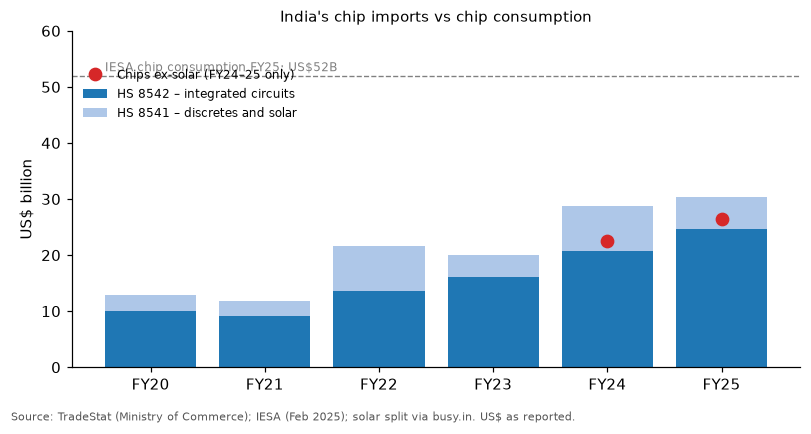

In [4]:
fig, ax = plt.subplots(figsize=(7.4, 3.9))
x = np.arange(len(tr))
ax.bar(x, tr['hs8542_imports_usd_m'] / 1000, color='#1f77b4', label='HS 8542 – integrated circuits')
ax.bar(x, tr['hs8541_imports_usd_m'] / 1000, bottom=tr['hs8542_imports_usd_m'] / 1000, color='#aec7e8', label='HS 8541 – discretes and solar')
m = tr['ex_solar_usd_m'].notna()
ax.plot(x[m], tr.loc[m, 'ex_solar_usd_m'] / 1000, 'o', color='#d62728', ms=8, label='Chips ex-solar (FY24–25 only)')
ax.axhline(52, color='grey', ls='--', lw=0.9); ax.text(-0.4, 52.8, 'IESA chip consumption FY25: US$52B', fontsize=8, color='grey')
ax.set_xticks(x); ax.set_xticklabels(tr['fiscal_year']); ax.set_ylabel('US$ billion'); ax.set_ylim(0, 60)
ax.set_title("India's chip imports vs chip consumption", fontsize=10); ax.legend(fontsize=8, frameon=False, loc='upper left', bbox_to_anchor=(0, 0.92))
fig.text(0.01, 0.005, 'Source: TradeStat (Ministry of Commerce); IESA (Feb 2025); solar split via busy.in. US$ as reported.', fontsize=7, color='#555')
plt.tight_layout(rect=[0, 0.03, 1, 1]); plt.savefig('../charts/chart_phase2_trade.png', dpi=200); plt.show()
tr.to_csv('../data/tradestat_with_ex_solar.csv', index=False); gt.to_csv('../data/phase2_gap_table.csv', index=False)

**Reading this:** loose-chip imports cover only about half of what India consumes. On Phase 2's definition, the rest arrives inside sub-assemblies, so real import dependence is close to 100% of chip value.

**Limitations:**
- The solar split is known only for FY24–25.
- The sub-assembly and valuation numbers are my assumptions, and they are the biggest drivers of the gap table.
- US$ figures are as reported by TradeStat, so the ₹95 rule does not apply to them.